### Comparação de classificadores na CTG

Este notebook escolhe os hiperparâmetros de quatro classificadores da statstech (regressão logística, LDA, QDA e KNN) por validaçaõ cruzada e compara-os. 


#### 0. Configuração inicial 

In [40]:
import csv
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
from statstech.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from statstech.linear_model import LogisticRegression
from statstech.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score
)
from statstech.neighbors import KNeighborsClassifier
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import FIGURES, PROCESSED, SEED, STYLE, TABLES
from analysis.evaluation import evaluate_classifier
from analysis.io import load_dataset
from analysis.validation import StratifiedGroupKFold

plt.style.use(STYLE)

warnings.filterwarnings("ignore", message=".*indefinid.*")

CLASS_NAMES = ["normal", "suspeito", "patológico"]
PATHOLOGICAL = 2

#### 1. Dados e grupos do treino

ctg.npz traz treino e teste já separados por registro. Para a validação cruzada também precisamos saber de qual registro veio cada dado do treino.

In [41]:
data = load_dataset("ctg")
X_train, y_train = data["X_train"], data["y_train"]
features_names = data["feature_names"].tolist()

groups_train = np.load(PROCESSED / "ctg_groups_train.npy")
assert len(groups_train) == len(y_train)

print(f"treino: {X_train.shape[0]} exames, {X_train.shape[1]} medidas, "
      f"{len(np.unique(groups_train))} registros")
for k, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train == k)
    print(f"  {name:11s} {n:5d}  ({n / len(y_train):.1%})")

treino: 1755 exames, 20 medidas, 282 registros
  normal       1363  (77.7%)
  suspeito      245  (14.0%)
  patológico    147  (8.4%)


#### 2. Validação cruzada por registro

Segmentos do mesmo registro são muito parecidos. Se um cai no treino de um fold e outro na validação, o modelo "reconhece" o vizinho e a nota sobe sem o modelo ter aprendido nada que generalize. 


In [42]:
cv = StratifiedGroupKFold(groups_train, n_splits=10, random_state=SEED)

##### 2.1 KNN com folds por linha e por registro 

Busca por k com duas validações diferentes, mas com fold por linha segmentos "irmãos" se misturam entre treino e validação.

In [43]:
def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

ks = [1, 5, 15, 31, 61]
cv_by_row = StratifiedKFold(10, shuffle=True, random_state=SEED)
for label, splitter in [("folds por linha", cv_by_row), ("folds por registro", cv)]:
    search = GridSearchCV(make_pipeline(KNeighborsClassifier()), {"model__n_neighbors": ks},
                          cv=splitter, scoring="f1_macro").fit(X_train, y_train)
    print(f"{label:19s} melhor k = {search.best_params_['model__n_neighbors']:2d}   "
          f"F1 por k: {[round(r['mean_score'], 3) for r in search.cv_results_]}")

folds por linha     melhor k =  1   F1 por k: [0.834, 0.804, 0.786, 0.762, 0.722]
folds por registro  melhor k = 15   F1 por k: [0.694, 0.722, 0.723, 0.704, 0.663]


#### 3. Classificador baseline

Prever sempre a classe majoritária.

In [44]:
majority_class = np.bincount(y_train). argmax()
baseline = evaluate_classifier(y_train, np.full_like(y_train, majority_class))
print(f"acurácia {baseline['accuracy']:.3f} F1 macro {baseline['f1_macro']:.3f} "
      f"recall patológico {baseline['recall_2']:.3f}")

acurácia 0.777 F1 macro 0.291 recall patológico 0.000


#### 4. Busca de hiperparâmetros (F1 macro)

-> F1 macro: média do F1 das três classes.



In [45]:
grids = {
    "logistic": {"model__alpha": [0, 0.01, 0.1, 1, 10]},
    "lda": {"model__reg_param": [1e-6, 1e-3, 1e-1]},
    "qda": {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5]},
    "knn": {"model__n_neighbors": [1, 5, 15, 31, 61]},
}
searches = {}


def show_search(search):
    # Uma linha por valor da grade, com a média ± desvio entre folds.
    results = search.cv_results_
    for i, r in enumerate(results):
        value = next(iter(r["params"].values()))
        mark = "  <- melhor" if i == search.best_index_ else ""
        print(f"  {value!s:>8}   {r['mean_score']:.3f} ± {r['std_score']:.3f}{mark}")
    #Quando o melhor valor é o primeiro ou o último da grade
    if search.best_index_ in (0, len(results) - 1):
        print("o melhor valor está na borda da grade.")

##### 4.1 Regressão Logística 

In [46]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression()), grids["logistic"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.786 ± 0.088  <- melhor
      0.01   0.786 ± 0.088
       0.1   0.786 ± 0.088
         1   0.781 ± 0.086
        10   0.776 ± 0.097
o melhor valor está na borda da grade.


Obs.: Como o melhor valor está na borda, talvez o modelo não tenha terminado de treinar. Vamos conferir inicialmente a convergência.

In [47]:
logistic = searches["logistic"].best_estimator_.named_steps_["model"]
loss = np.asarray(logistic.loss_history_)
print(f"iterações: {len(loss)} de max_iter = {logistic.max_iter}")
print(f"queda da perda nas últimas 100 iterações: {loss[-101] - loss[-1]:.4f}")

iterações: 1000 de max_iter = 1000
queda da perda nas últimas 100 iterações: 0.0022


A perda ainda estava caindo no final -> provavelmente não convergiu. 
Ideia: mais iterações ou passos maiores. 

In [48]:
alpha = searches["logistic"].best_params_["model__alpha"]
curves = {}
print("learning_rate  iterações  perda final  convergiu  perda sempre caindo")
for lr in [0.1, 0.5, 1.0, 2.0, 5.0]:
    model = make_pipeline(LogisticRegression(alpha=alpha, learning_rate=lr, max_iter=5000))
    history = np.asarray(model.fit(X_train, y_train).named_steps_["model"].loss_history_)
    curves[lr] = history
    print(f"{lr:13g}  {len(history):9d}  {history[-1]:11.4f}  {len(history) < 5000!s:>9}  "
          f"{bool(np.all(np.diff(history) <= 0))!s:>19}")

learning_rate  iterações  perda final  convergiu  perda sempre caindo
          0.1       5000       0.2118      False                 True
          0.5       2869       0.2064       True                 True
            1       1881       0.2057       True                 True
            2       1201       0.2054       True                 True
            5       5000       0.4058      False                False


Learning_rate = 1.0 é uma boa decisão entre os valores que convergem com a perda caindo. (Passos grandes são seguros pois as medidas estão padronizadas)

-> Nova busca, com o novo passo: 

In [49]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.774 ± 0.083
      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
o melhor valor está na borda da grade.


Agora o melhor `alpha` é o 10 (último da grade). Vamos estender o grid para ver se a nota continua aumentando:

In [50]:
grids["logistic"] = {"model__alpha": [0, 0.01, 0.1, 1, 10, 20, 100]}
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.774 ± 0.083
      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
        20   0.774 ± 0.092
       100   0.723 ± 0.074


##### 4.2 LDA

In [51]:
searches["lda"] = GridSearchCV(
    make_pipeline(LinearDiscriminantAnalysis()), grids["lda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["lda"])

     1e-06   0.715 ± 0.092  <- melhor
     0.001   0.712 ± 0.090
       0.1   0.708 ± 0.085
o melhor valor está na borda da grade.


Obs.: o valor está na borda, mas as três notas são quase iguais e um valor abaixo de 1e-6 praticamente não regulariza nada.

##### 4.3 QDA

In [52]:
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
o melhor valor está na borda da grade.


Vamos estender a grade para observar se de fato 0.5 é o melhor: 

In [53]:
grids["qda"] = {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5, 0.7, 0.9]}
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
       0.7   0.732 ± 0.109
       0.9   0.730 ± 0.109


De 0.5 a 0.9 a nota fica estável, então `reg_param = 0.5` é suficiente.

##### 4.4 KNN

In [54]:
searches["knn"] = GridSearchCV(
    make_pipeline(KNeighborsClassifier()), grids["knn"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["knn"])

         1   0.694 ± 0.102
         5   0.722 ± 0.097
        15   0.723 ± 0.067  <- melhor
        31   0.704 ± 0.075
        61   0.663 ± 0.097


##### 4.5 Nota x hiperparâmetro

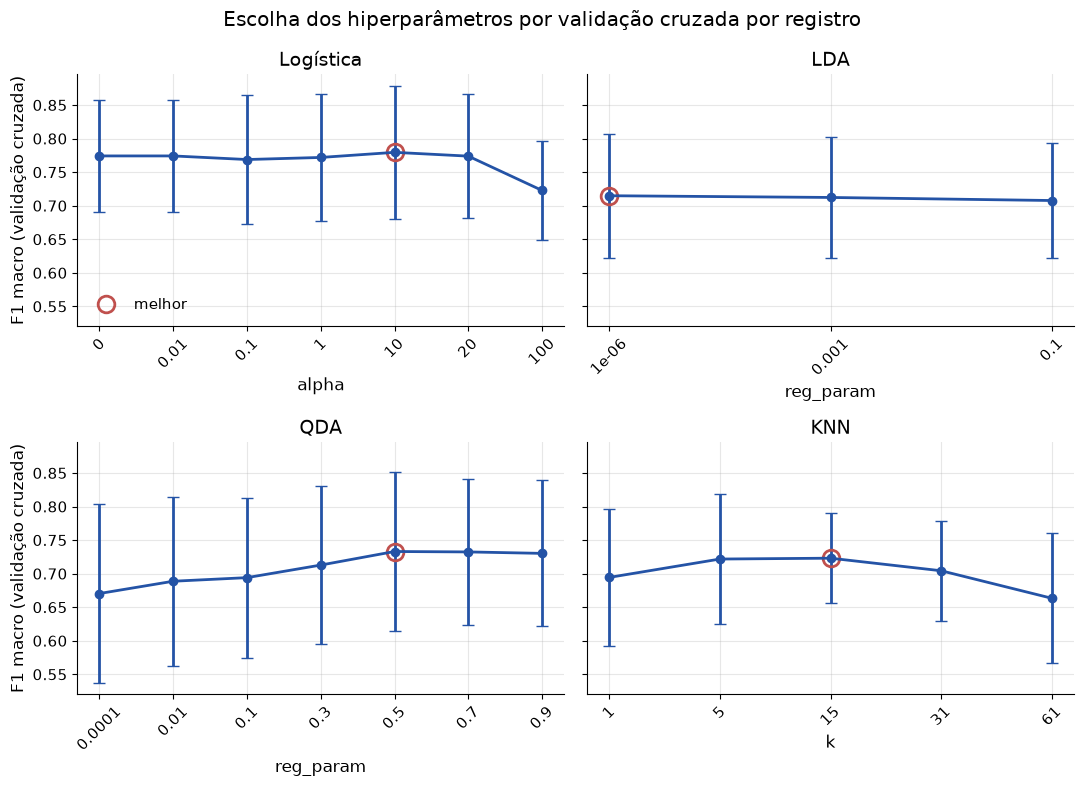

In [ ]:
LABELS = {"logistic": "Logística", "lda": "LDA", "qda": "QDA", "knn": "KNN"}


def plot_search_curve(search, ax, title, xlabel):
    # TODO trocar pelo plot_search do C7
    results = search.cv_results_
    values = [next(iter(r["params"].values())) for r in results]
    mean = np.array([r["mean_score"] for r in results])
    std = np.array([r["std_score"] for r in results])
    x = np.arange(len(values))
    ax.errorbar(x, mean, yerr=std, marker="o", capsize=4)
    ax.plot(x[search.best_index_], mean[search.best_index_], "o", ms=12,
            mfc="none", mec="C1", mew=2, label="melhor")
    ax.set_xticks(x, [f"{v:g}" for v in values], rotation=45)
    ax.set_title(title)
    ax.set_xlabel(xlabel)


x_labels = {"logistic": "alpha", "lda": "reg_param", "qda": "reg_param", "knn": "k"}
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, (key, search) in zip(axes.flat, searches.items()):
    plot_search_curve(search, ax, LABELS[key], x_labels[key])
for ax in axes[:, 0]:
    ax.set_ylabel("F1 macro (validação cruzada)")
axes[0, 0].legend()
fig.suptitle("Escolha dos hiperparâmetros por validação cruzada por registro")
fig.tight_layout()
fig.savefig(FIGURES / "ctg_busca.png")
plt.show()